# 🧪 Scriber Labs: Mesoscale ZBW Ensembles

This notebook demonstrates the **ZBW Kuramoto Data Generator**, a specialized simulation engine for mesoscale ensembles. It features:
1. **The phi-Shield**: A worst-case irrational frequency distribution based on the Golden Ratio.
2. **Sparse Coprime Adjacency**: A network topology where nodes are coupled only if their indices are coprime.
3. **LED Macroscopic Vector Torque**: An external driving field modeling Critical Flicker Fusion (CFF) effects.

In [1]:
from __future__ import annotations
import numpy as np
import matplotlib.pyplot as plt
from kuramoto.analysis.viz import set_style, SCRIBER_PALETTE
from kuramoto.models import ZBWKuramotoDataGenerator

set_style()

print("🚀 ZBWKuramotoDataGenerator imported from kuramoto.models.")

🚀 ZBWKuramotoDataGenerator imported from kuramoto.models.


## 🏃‍♂️ Simulation Run

We use a simple Euler integration to observe the mesoscale dynamics.

In [2]:
# Setup
N = 50
gen = ZBWKuramotoDataGenerator(num_oscillators=N, coupling_K=1.2)
dt = 0.001
t_max = 0.5
steps = int(t_max / dt)
times = np.linspace(0, t_max, steps)

phases = np.random.uniform(0, 2*np.pi, N)
history = np.zeros((steps, N))
order_param = np.zeros(steps, dtype=complex)

# Evolution
for i in range(steps):
    history[i] = phases
    order_param[i] = gen.compute_order_parameter(phases)
    dtheta = gen.phase_evolution_derivatives(times[i], phases, led_frequency=60.0, led_amplitude=2.0)
    phases += dtheta * dt
    phases %= 2*np.pi

print("✅ Simulation complete.")

✅ Simulation complete.


## 📊 Visualization

Plotting the order parameter magnitude $r(t)$ and the phase trajectories.

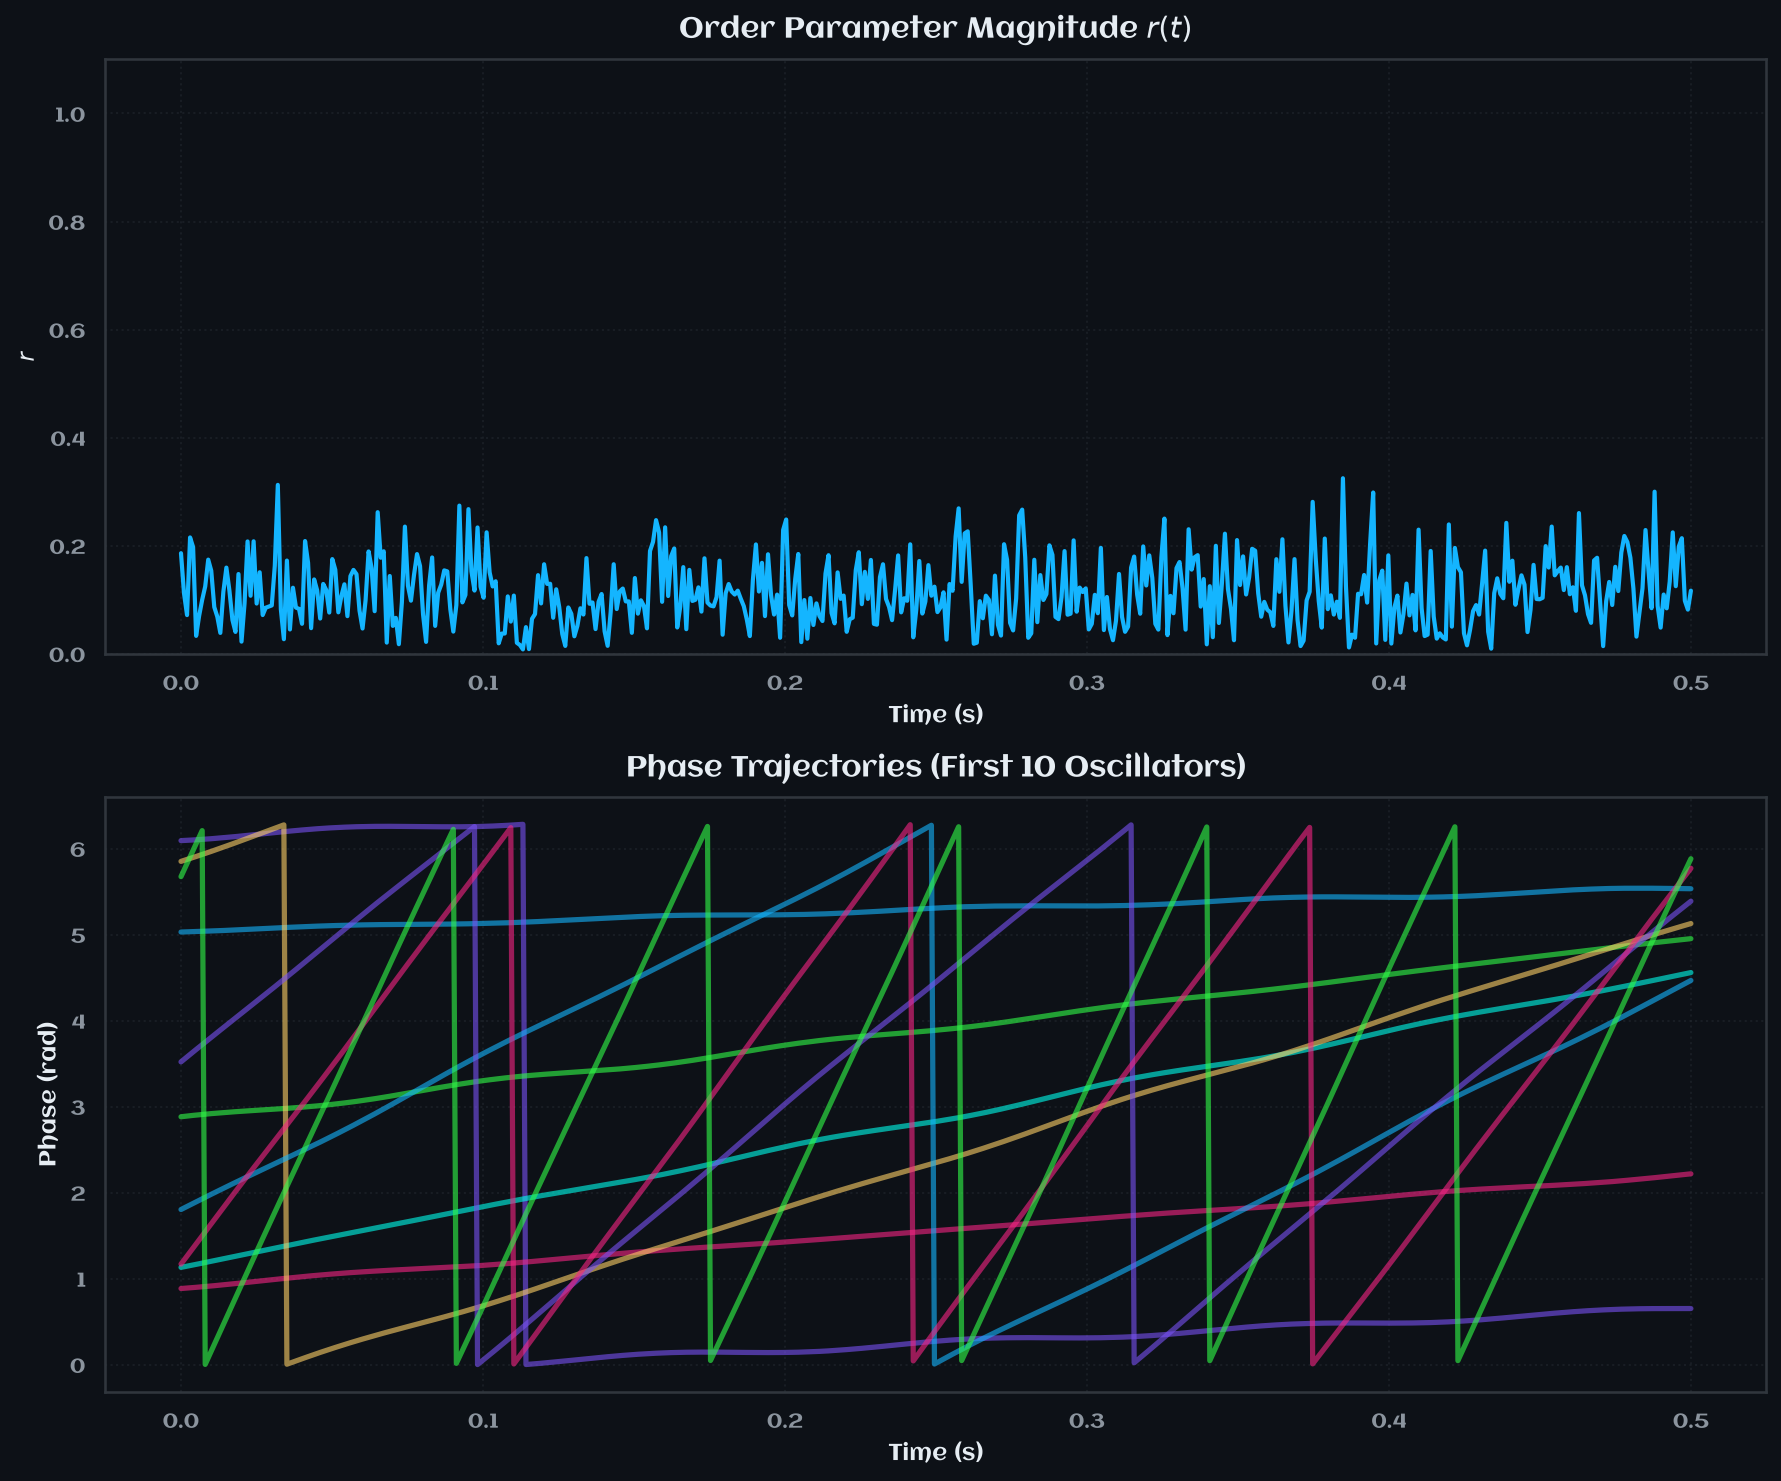

In [3]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10))

r = np.abs(order_param)
ax1.plot(times, r, color=SCRIBER_PALETTE['accent_cyan'], lw=2)
ax1.set_title("Order Parameter Magnitude $r(t)$", fontsize=14)
ax1.set_xlabel("Time (s)")
ax1.set_ylabel("$r$")
ax1.set_ylim(0, 1.1)

for i in range(min(N, 10)):
    ax2.plot(times, history[:, i], alpha=0.6)
ax2.set_title("Phase Trajectories (First 10 Oscillators)", fontsize=14)
ax2.set_xlabel("Time (s)")
ax2.set_ylabel("Phase (rad)")

plt.tight_layout()
plt.show()